In [ ]:
!pip install -q -U kaggle

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [ ]:
!kaggle datasets download -d ealaxi/paysim1 -p /content/data
!unzip -o -q /content/data/paysim1.zip -d /content/data
!ls -lh /content/data

Dataset URL: https://www.kaggle.com/datasets/ealaxi/paysim1
License(s): CC-BY-SA-4.0
100% 178M/178M [00:01<00:00, 101MB/s]

total 649M
-rw-r--r-- 1 root root 178M Sep 20  2019 paysim1.zip
-rw-r--r-- 1 root root 471M Sep 20  2019 PS_20174392719_1491204439457_log.csv


In [ ]:
import hashlib

path = "/content/data/PS_20174392719_1491204439457_log.csv"
h = hashlib.sha256()
with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        h.update(chunk)
print(h.hexdigest())

16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b


In [ ]:
import pandas as pd

df = pd.read_csv(path)

print(df.shape)
print(df.isFraud.sum(), round(df.isFraud.mean() * 100, 3))
print(df.isnull().sum().sum())
print(df.duplicated().sum())
print(df.nameOrig.nunique(), df.nameDest.nunique())
print(df.step.min(), df.step.max())
print(df[df.isFraud == 1].type.value_counts())

steps = sorted(df.step.unique())
n = len(steps)
s1, s2 = steps[int(n * 0.6) - 1], steps[int(n * 0.8) - 1]
part = pd.cut(df.step, [0, s1, s2, df.step.max()], labels=["train", "val", "test"])
print(s1, s2)
print(df.groupby(part, observed=True).isFraud.agg(["count", "sum", "mean"]))

(6362620, 11)
8213 0.129
0
0
6353307 2722362
1 743
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64
445 594
         count   sum      mean
step                          
train  6010937  5007  0.000833
val     228103  1552  0.006804
test    123580  1654  0.013384


# Complements audit S2

Ces cellules completent l'audit de base. On suppose que `df` est deja charge avec le CSV PaySim.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

## 1. Frequence des comptes

Combien de comptes apparaissent 1 fois, 2 fois, entre 3 et 10 fois, ou plus de 10 fois, cote emetteur et cote beneficiaire.

In [ ]:
def freq_buckets(s):
    c = s.value_counts()
    b = pd.cut(c, [0, 1, 2, 10, np.inf], labels=["1 fois", "2 fois", "3 a 10 fois", "plus de 10 fois"])
    return b.value_counts().sort_index()

print(freq_buckets(df.nameOrig))
print(freq_buckets(df.nameDest))

count
1 fois             6344009
2 fois                9283
3 a 10 fois             15
plus de 10 fois          0
Name: count, dtype: int64
count
1 fois             2262704
2 fois               77054
3 a 10 fois         252318
plus de 10 fois     130286
Name: count, dtype: int64


## 2. Comptes a la fois emetteurs et beneficiaires

D'abord le recouvrement global, puis la version qui compte vraiment pour le graphe : pour chaque transaction, est ce que l'emetteur etait deja apparu comme beneficiaire a une heure strictement anterieure.

In [ ]:
orig = set(df.nameOrig)
dest = set(df.nameDest)
both = orig & dest
print(len(both), round(len(both) / len(orig | dest) * 100, 3))

1769 0.019


In [ ]:
first_dest = df.groupby("nameDest").step.min()
prev = df.nameOrig.map(first_dest)
seen = prev < df.step
print(seen.sum(), round(seen.mean() * 100, 3))
print(df.loc[seen, "isFraud"].sum(), df.loc[seen, "isFraud"].mean())

900 0.014
0 0.0


## 3. Transferts repetes entre les deux memes comptes

In [ ]:
pairs = df.groupby(["nameOrig", "nameDest"]).size()
print(len(pairs), (pairs > 1).sum(), pairs.max())

6362620 0 1


## 4. Distribution des montants, fraude contre normal

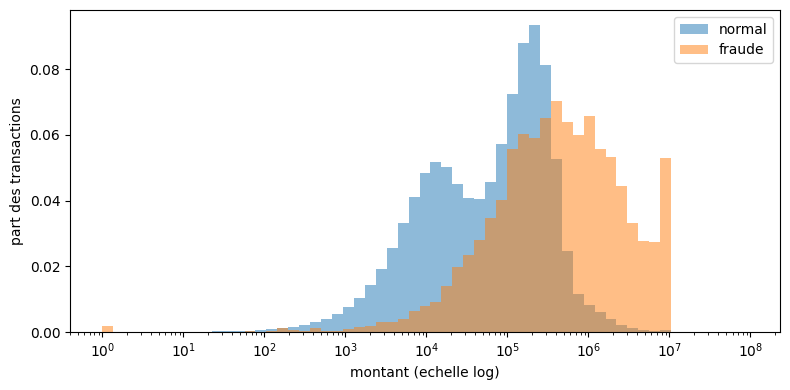

             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  
16
287


In [ ]:
bins = np.logspace(0, np.log10(df.amount.max() + 1), 60)
a0 = df.loc[df.isFraud == 0, "amount"] + 1
a1 = df.loc[df.isFraud == 1, "amount"] + 1

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(a0, bins=bins, alpha=0.5, weights=np.ones(len(a0)) / len(a0), label="normal")
ax.hist(a1, bins=bins, alpha=0.5, weights=np.ones(len(a1)) / len(a1), label="fraude")
ax.set_xscale("log")
ax.set_xlabel("montant (echelle log)")
ax.set_ylabel("part des transactions")
ax.legend()
plt.tight_layout()
plt.savefig("figures/montants_fraude_vs_normal.png", dpi=150)
plt.show()

print(df.groupby("isFraud").amount.describe())
print((df.loc[df.isFraud == 1, "amount"] == 0).sum())
print((df.loc[df.isFraud == 1, "amount"] == 10_000_000).sum())

## 5. Transactions et fraudes par jour simule

Un jour = 24 steps. Les traits pointilles marquent les bornes des partitions (steps 445 et 594).

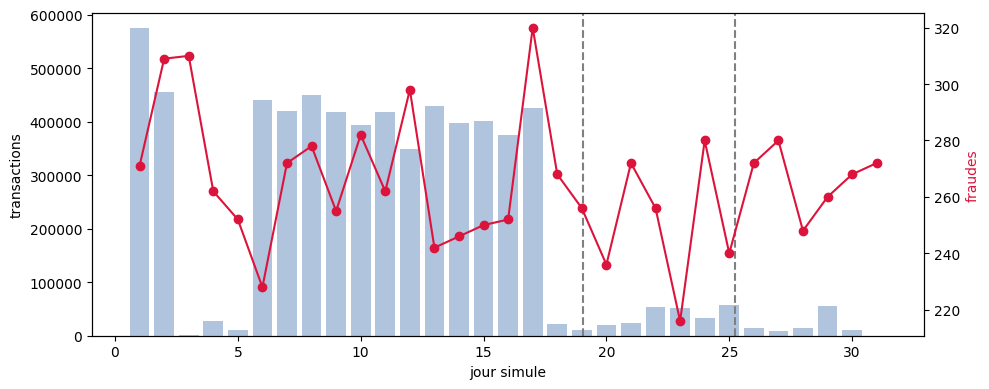

     transactions  fraudes      taux
day                                 
1          574255      271  0.000472
2          455238      309  0.000679
3            1070      310  0.289720
4           28240      262  0.009278
5            9789      252  0.025743
6          441005      228  0.000517
7          420583      272  0.000647
8          449637      278  0.000618
9          417919      255  0.000610
10         392945      282  0.000718
11         417859      262  0.000627
12         349776      298  0.000852
13         428583      242  0.000565
14         397876      246  0.000618
15         401282      250  0.000623
16         375594      252  0.000671
17         425766      320  0.000752
18          20999      268  0.012763
19          11300      256  0.022655
20          19727      236  0.011963
21          24593      272  0.011060
22          53437      256  0.004791
23          51012      216  0.004234
24          32709      280  0.008560
25          57853      240  0.004148
2

In [ ]:
df["day"] = (df.step - 1) // 24 + 1
daily = df.groupby("day").agg(transactions=("isFraud", "size"), fraudes=("isFraud", "sum"))
daily["taux"] = daily.fraudes / daily.transactions

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(daily.index, daily.transactions, color="lightsteelblue")
ax1.set_xlabel("jour simule")
ax1.set_ylabel("transactions")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily.fraudes, color="crimson", marker="o")
ax2.set_ylabel("fraudes", color="crimson")
for s in [445, 594]:
    ax1.axvline(s / 24 + 0.5, ls="--", color="gray")
plt.tight_layout()
plt.savefig("figures/transactions_fraudes_par_jour.png", dpi=150)
plt.show()

print(daily)

## 6. Taux de fraude par type d'operation

In [ ]:
print(df.groupby("type").isFraud.agg(["count", "sum", "mean"]).sort_values("mean", ascending=False))

            count   sum      mean
type                             
TRANSFER   532909  4097  0.007688
CASH_OUT  2237500  4116  0.001840
CASH_IN   1399284     0  0.000000
DEBIT       41432     0  0.000000
PAYMENT   2151495     0  0.000000


## 7. Comptes marchands

In [ ]:
merch = df.nameDest.str.startswith("M")
print(merch.sum(), df.nameOrig.str.startswith("M").sum())
print(df.loc[merch, "type"].value_counts())
print((df.loc[merch, ["oldbalanceDest", "newbalanceDest"]] != 0).any(axis=1).sum())
print(df.loc[merch, "isFraud"].sum())

2151495 0
type
PAYMENT    2151495
Name: count, dtype: int64
0
0


## 8. Incoherences de soldes

Seulement sur TRANSFER et CASH_OUT, les seuls types avec des fraudes. Ces calculs utilisent les soldes apres transaction : ils servent a justifier le contrat de variables, pas a creer des features pour le protocole principal.

In [ ]:
tc = df[df.type.isin(["TRANSFER", "CASH_OUT"])]
err_orig = (tc.oldbalanceOrg - tc.amount - tc.newbalanceOrig).abs() > 0.01
err_dest = (tc.oldbalanceDest + tc.amount - tc.newbalanceDest).abs() > 0.01
vide = (tc.amount - tc.oldbalanceOrg).abs() < 0.01

print(pd.crosstab(tc.isFraud, err_orig, normalize="index").round(3))
print(pd.crosstab(tc.isFraud, err_dest, normalize="index").round(3))
print(pd.crosstab(tc.isFraud, vide, normalize="index").round(3))

col_0    False  True 
isFraud              
0        0.095  0.905
1        0.995  0.005
col_0    False  True 
isFraud              
0        0.774  0.226
1        0.435  0.565
col_0    False  True 
isFraud              
0        1.000  0.000
1        0.022  0.978


# Ancienneté des comptes

In [ ]:
first_seen = pd.concat([
    df[["nameOrig", "step"]].rename(columns={"nameOrig": "acc"}),
    df[["nameDest", "step"]].rename(columns={"nameDest": "acc"})
]).groupby("acc").step.min()

df["age_orig"] = df.step - df.nameOrig.map(first_seen)
df["age_dest"] = df.step - df.nameDest.map(first_seen)

print(round((df.age_orig == 0).mean() * 100, 2), round((df.age_dest == 0).mean() * 100, 2))
print(df.groupby("isFraud")[["age_orig", "age_dest"]].median())

99.84 43.52
         age_orig  age_dest
isFraud                    
0             0.0       8.0
1             0.0       0.0


# Diversité des voisins

In [ ]:
div = df.groupby("nameDest").nameOrig.nunique()
print(div.describe())
print(pd.cut(div, [0, 1, 2, 10, 50, np.inf]).value_counts().sort_index())

fraud_dest = df.loc[df.isFraud == 1, "nameDest"].unique()
print(div.loc[fraud_dest].describe())

count    2.722362e+06
mean     2.337169e+00
std      4.549264e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.130000e+02
Name: nameOrig, dtype: float64
nameOrig
(0.0, 1.0]      2262704
(1.0, 2.0]        77054
(2.0, 10.0]      252318
(10.0, 50.0]     129253
(50.0, inf]        1033
Name: count, dtype: int64
count    8169.000000
mean        8.036235
std         9.811278
min         1.000000
25%         1.000000
50%         4.000000
75%        11.000000
max        89.000000
Name: nameOrig, dtype: float64


# Analyse séparée de isFlaggedFraud

In [ ]:
print(df.isFlaggedFraud.sum())
print(pd.crosstab(df.isFlaggedFraud, df.isFraud))

16
isFraud               0     1
isFlaggedFraud               
0               6354407  8197
1                     0    16
